In [1]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')


Dependencies OK.


In [2]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cpu


---
## Step 1 — Data Loading, Curation & Label Assignment


In [3]:
# ──  Load ────────────────────────────────────────────────────────────────
df_raw = pd.read_csv('combined_hepg2_casepase.csv',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe())


Raw rows : 7,716
PUBCHEM_ACTIVITY_OUTCOME
Inactive        7172
Inconclusive     303
Active           241
Name: count, dtype: int64
count    7716.000000
mean        2.222136
std        10.344257
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       100.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [4]:
# ──   SMILES + deduplication ──────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi)) #converts to mol object, returns None if invalid
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')


[10:08:25] WARNING: not removing hydrogen atom without neighbors


After parse : 7,716  (removed 0 invalid SMILES)
After dedup : 7,714


Removed 294 inconclusive
Active   (1): 249
Inactive (0): 7,171
Ratio       : 28.8:1


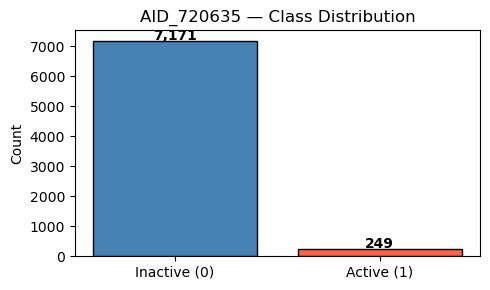

In [5]:
# ── Binary Labels
#  Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
n_inc = df['label'].isna().sum()
df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('AID_720635 — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('class_dist.png',dpi=150); plt.show()


---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN


In [6]:
# ── 5. Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')


[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerator
[10:08:40] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (7420, 2048)
FP density         : 0.0135


[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator
[10:08:41] DEPRECATION WARNING: please use MorganGenerator


In [9]:
# ──  Rich Atom Features (14-dim) & Bond Features (6-dim) — for GNN ─────────
#
#  14 atom features 
#    Atomic num one-hot (C,N,O,S,F,P,Cl,Br,I,other=10),
#    degree (0-5), formal charge, hybridization one-hot (SP/SP2/SP3/other=4),
#    is_aromatic, is_in_ring, total_Hs (0-4), normalized mass
#
#  6 bond features:
#    bond type one-hot (single/double/triple/aromatic=4),
#    is_conjugated, is_in_ring
#
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass   # 'other' → all zeros
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5) #no of bonds this atom has
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge() #chareg positve or nehative or zero
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

# Test dimensions
from rdkit.Chem import MolFromSmiles
_mol = MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')


Atom feature dim : 27
Bond feature dim : 6


In [10]:
# ── 7. Build Graph Dataset ───────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    # Atom features
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    # Bond features + bidirectional edges
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')


[10:08:59] WARNING: not removing hydrogen atom without neighbors


Graphs built: 7,420
Example: Data(x=[5, 27], edge_index=[2, 8], edge_attr=[8, 6], y=[1])


---
## Step 3 — 80/20/20 Split + Downsampling


In [11]:
# ── 8. 20% External Test Split ───────────────────────────────────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

# Parallel split for graph data (using same indices)
idx_all   = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={( y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')


Pool : 5,936  (act=199, ina=5737)
Test : 1,484  (act=50, ina=1434)


In [14]:
# ── Print Test Set Values ─────────────────────────────────────────────────────
df_test = df.iloc[idx_test].reset_index(drop=True).copy()
df_test['label'] = y_test

print(f'Test set size : {len(df_test):,} compounds')
print(f'X_test shape  : {X_test.shape}   (compounds × ECFP4 bits)')
print(f'y_test shape  : {y_test.shape}')
print(f'\nClass distribution:')
print(f'  Active   (1): {(y_test == 1).sum():,}')
print(f'  Inactive (0): {(y_test == 0).sum():,}')

print(f'\n── First 10 test set compounds ──')
display(df_test[['PUBCHEM_CID', 'csmi', 'PUBCHEM_ACTIVITY_SCORE', 'label']].head(20))

print(f'\n── Fingerprint values (X_test) — first 5 rows, first 20 bits ──')
print(X_test[:5, :20])

print(f'\n── Labels (y_test) — first 20 values ──')
print(y_test[:50])


Test set size : 1,484 compounds
X_test shape  : (1484, 2048)   (compounds × ECFP4 bits)
y_test shape  : (1484,)

Class distribution:
  Active   (1): 50
  Inactive (0): 1,434

── First 10 test set compounds ──


,PUBCHEM_CID,csmi,PUBCHEM_ACTIVITY_SCORE,label
0,439280,N[C@@H](Cc1c[nH]c2ccc(O)cc12)C(=O)O,0,0
1,71651,O=C(O)CCNC(=O)c1ccccc1,0,0
2,21804,CCOP(=O)(OCC)Oc1nc(Cl)c(Cl)cc1Cl,0,0
3,12124,CC(=O)Nc1cccc(O)c1,0,0
4,135403591,Cn1cnc2c(=O)[nH]c(N)nc21,0,0
5,8247,CC(=O)NNc1ccccc1,0,0
6,13514,CC(=O)C(Cl)(Cl)Cl,0,0
7,16212610,CCCCCCCCCCCCCC[P+](CCCCCC)(CCCCCC)CCCCCC.F[P-]...,41,1
8,28532,N#Cc1cc([N+](=O)[O-])ccc1N,0,0
9,34051,Cc1cccc(N(C)C(=S)Oc2ccc3c(c2)CCC3)c1,0,0



── Fingerprint values (X_test) — first 5 rows, first 20 bits ──
[[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

── Labels (y_test) — first 20 values ──
[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [15]:
# ── 80/20 Train/Val Split from Pool ────────────────────────────────────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val  = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')


Train-raw: 4,748  (act=159, ina=4589)
Val      : 1,188  (act=40,  ina=1148)


In [16]:
# ──  Downsampling on TRAIN ONLY ──────────────────────────────
act_idx_tr  = np.where(y_tr_raw == 1)[0]
ina_idx_tr  = np.where(y_tr_raw == 0)[0]
n_act_tr    = len(act_idx_tr)

rng = np.random.RandomState(SEED)
#changing to 5:1
sampled_ina = rng.choice(ina_idx_tr, size=n_act_tr * 5, replace=False)

train_idx   = np.concatenate([act_idx_tr, sampled_ina])
rng.shuffle(train_idx)

X_train = X_tr_raw[train_idx]
y_train = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (5:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (real-world imbalance): {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')


Balanced TRAIN: 954  act=159 / ina=795 (5:1)
VAL  (real-world imbalance): 1,188  ratio=28.7:1
TEST (real-world imbalance): 1,484  ratio=28.7:1


Split summary (% of total)
  Train:   954 (12.9%)  act=159, ina=795
  Val  : 1,188 (16.0%)  act=40, ina=1148
  Test : 1,484 (20.0%)  act=50, ina=1434


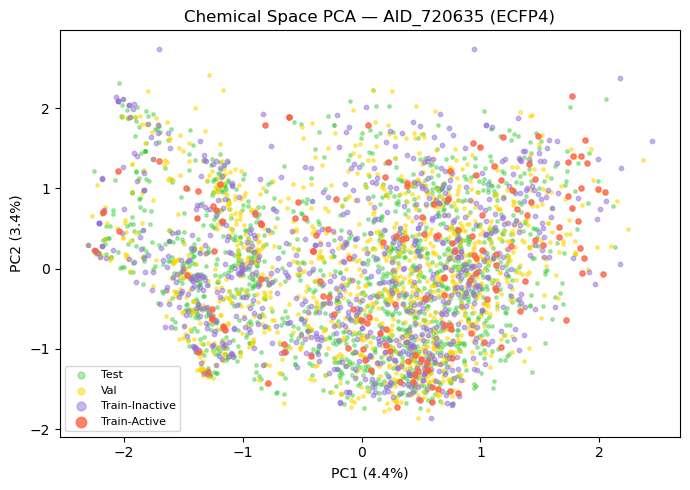

In [17]:
# ── 11. Split Summary & Chemical Space PCA ───────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={( ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — AID_720635 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('chem_space.png',dpi=150); plt.show()


Left-out inactives : 3,794
PC1: 4.4%  PC2: 3.4%  PC3: 2.8%
Total variance explained: 10.5%


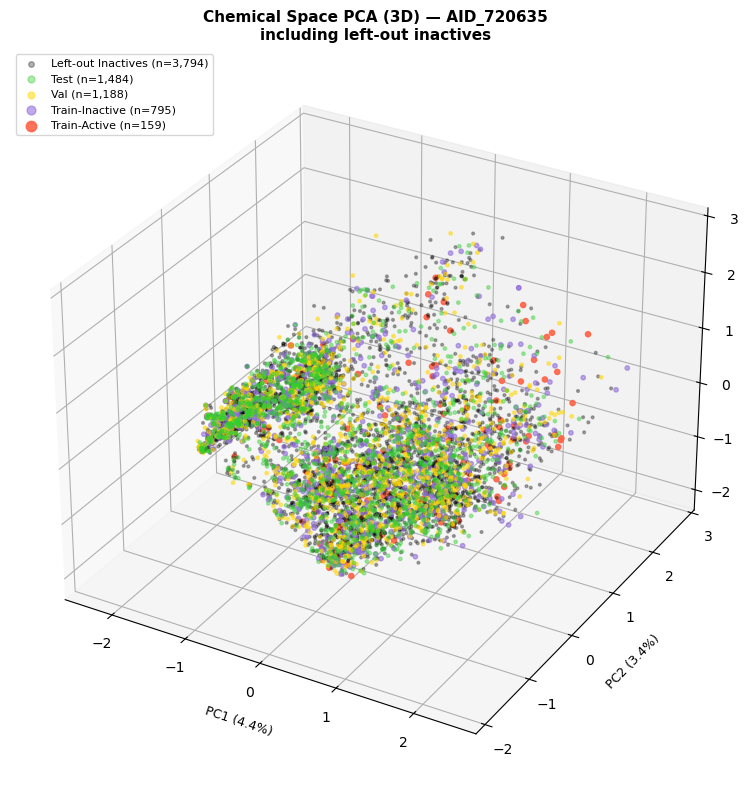

In [18]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# ── Find the left-out (discarded) inactives ──────────────────────────────────
sampled_set     = set(sampled_ina.tolist())          # the 904 kept inactives
leftout_idx_tr  = np.array([idx for idx in ina_idx_tr 
                             if idx not in sampled_set])  # the 1,152 discarded
X_leftout       = X_tr_raw[leftout_idx_tr]           # their fingerprints

print(f'Left-out inactives : {len(leftout_idx_tr):,}')  # should be 1,152

# ── 3-component PCA ──────────────────────────────────────────────────────────
pca3 = PCA(n_components=3, random_state=SEED)
pca3.fit(X_train)          # fit on balanced training set only

# Transform all sets including leftout
tr_3  = pca3.transform(X_train)    # (1808, 3) balanced train
va_3  = pca3.transform(X_val)      # ( 740, 3) val
te_3  = pca3.transform(X_test)     # ( 925, 3) test
lo_3  = pca3.transform(X_leftout)  # (1152, 3) discarded inactives

pc1_var = pca3.explained_variance_ratio_[0]*100
pc2_var = pca3.explained_variance_ratio_[1]*100
pc3_var = pca3.explained_variance_ratio_[2]*100

print(f'PC1: {pc1_var:.1f}%  PC2: {pc2_var:.1f}%  PC3: {pc3_var:.1f}%')
print(f'Total variance explained: {pc1_var+pc2_var+pc3_var:.1f}%')

# ── 3D Plot ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection='3d')

# Plot each group
ax.scatter(lo_3[:,0], lo_3[:,1], lo_3[:,2],
           c='black', s=4, alpha=0.3, label=f'Left-out Inactives (n={len(lo_3):,})')

ax.scatter(te_3[:,0], te_3[:,1], te_3[:,2],
           c='limegreen', s=6, alpha=0.4, label=f'Test (n={len(te_3):,})')

ax.scatter(va_3[:,0], va_3[:,1], va_3[:,2],
           c='gold', s=6, alpha=0.5, label=f'Val (n={len(va_3):,})')

ax.scatter(tr_3[y_train==0, 0], tr_3[y_train==0, 1], tr_3[y_train==0, 2],
           c='mediumpurple', s=10, alpha=0.6, label=f'Train-Inactive (n={(y_train==0).sum():,})')

ax.scatter(tr_3[y_train==1, 0], tr_3[y_train==1, 1], tr_3[y_train==1, 2],
           c='tomato', s=14, alpha=0.9, label=f'Train-Active (n={(y_train==1).sum():,})')

# Labels
ax.set_xlabel(f'PC1 ({pc1_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_ylabel(f'PC2 ({pc2_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_zlabel(f'PC3 ({pc3_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_title('Chemical Space PCA (3D) — AID_720635\nincluding left-out inactives',
             fontsize=11, fontweight='bold')

ax.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('chem_space_3d.png', dpi=150)
plt.show()


---
## Step 4 — Evaluation Helpers


In [19]:
# ── 12. Metrics Helper ────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')


Helpers ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning on Validation Set

Train on balanced training set → tune on (imbalanced) validation set by **ROC-AUC** → final eval on test.


In [20]:
# ── 13. Random Forest Grid Search ────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'  : [300, 500],
    'max_features'  : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'     : [None, 20]
})

best_rf_auc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_rf_auc:
        best_rf_auc, best_rf, best_rf_params = auc, clf, p

print(f'Best RF  val AUC={best_rf_auc:.4f}  params={best_rf_params}')


RF: 16 configs...
Best RF  val AUC=0.8198  params={'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}


In [21]:
# ── 14. SVM Grid Search ───────────────────────────────────────────────────────
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_auc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_svm_auc:
        best_svm_auc, best_svm, best_svm_params = auc, clf, p

print(f'Best SVM val AUC={best_svm_auc:.4f}  params={best_svm_params}')


SVM: 9 configs...
Best SVM val AUC=0.8556  params={'C': 1, 'gamma': 0.01}


In [22]:
# ── 15. XGBoost Grid Search ──────────────────────────────────────────────────
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_auc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_xgb_auc:
        best_xgb_auc, best_xgb, best_xgb_params = auc, clf, p

print(f'Best XGB val AUC={best_xgb_auc:.4f}  params={best_xgb_params}')


XGB: 12 configs...
Best XGB val AUC=0.8019  params={'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 500, 'subsample': 0.8}


In [23]:
# ── 16. Classical ML — Val & Test Evaluation ─────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n,clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n,clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model','CPT']))
print('\n── Classical ML — Test Set ──')
display(df_cl_test.set_index(['Model','CPT']))


── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         17.5         99.0  58.2   0.8198  0.2815  0.2366   
              0.8          2.5        100.0  51.2   0.8198  0.2815  0.1555   
SVM           0.5         17.5         99.0  58.3   0.8556  0.2723  0.2443   
              0.8          2.5        100.0  51.2   0.8556  0.2723  0.1555   
XGBoost       0.5         37.5         94.3  65.9   0.8019  0.2493  0.2292   
              0.8         20.0         97.9  59.0   0.8019  0.2493  0.1995   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     58.2  0.2373  
              0.8     51.2  0.0488  
SVM           0.5     58.3  0.2414  
              0.8     51.2  0.0488  
XGBoost       0.5     65.9  0.2500  
              0.8     59.0  0.2222


── Classical ML — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         20.0         98.6  59.3   0.8202  0.2216  0.2385   
              0.8          4.0        100.0  52.0   0.8202  0.2216  0.1967   
SVM           0.5         20.0         98.6  59.3   0.8144  0.1817  0.2385   
              0.8          0.0        100.0  50.0   0.8144  0.1817  0.0000   
XGBoost       0.5         46.0         92.8  69.4   0.8021  0.1606  0.2513   
              0.8         34.0         97.1  65.5   0.8021  0.1606  0.2869   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     59.3  0.2500  
              0.8     52.0  0.0769  
SVM           0.5     59.3  0.2500  
              0.8     50.0  0.0000  
XGBoost       0.5     69.4  0.2614  
              0.8     65.5  0.3119

---
## Step 6 — Graph Neural Networks (Classification)

**Architecture** (same for all 4 variants):
```
SMILES  Atoms+Bonds (27-dim / 6-dim)
  - Linear projection (hidden)
  - 3 × [Conv + BatchNorm1d + ReLU + Dropout + Residual]
  - GlobalMeanPool
  - MLP head [hidden→hidden/2→1]
  - BCEWithLogitsLoss
```
Tuned hyperparameters per architecture: `hidden`, `n_layers`, `dropout`, `lr`  
Selection criterion: **val ROC-AUC** | Early stopping patience=20 epochs


In [24]:
# ── 17. GNN Architecture ─────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """
     GNN for molecular binary classification.
     GCN, GAT, GIN, GraphSAGE via conv_type argument.
    3 conv layers with BatchNorm + Residual connections.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        # Input projection
        self.proj = nn.Linear(in_dim, hidden) #linear layer to project input features to hidden dim
        self.bn0  = nn.BatchNorm1d(hidden) #batch norm after input projection

        # Conv layers + BatchNorm
        self.convs = nn.ModuleList() #list to hold convolutional layers
        self.bns   = nn.ModuleList() #list to hold batch norm layers after each conv
        for _ in range(n_layers): 
#             GCNConv(128, 128):
# Each atom collects messages from neighbours
# → takes weighted average
# → updates its own 128 numbers

            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                # concat=False → output stays at hidden dim
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden*2),
                    nn.BatchNorm1d(hidden*2),
                    nn.ReLU(),
                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        # MLP classification head
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden//2, 1)   # logit output for BCEWithLogitsLoss
        )

    def forward(self, x, edge_index, batch):
        # Input projection
        x = F.relu(self.bn0(self.proj(x)))
        x = self.drop(x)
        # Conv layers with residual connections
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + x_res          # skip connection (same dim)
        # Global readout + head
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)   # (B,)

print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')


MolGNN defined. ATOM_DIM=27


In [25]:
# ── 18. Training & Evaluation Functions ──────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc

print('Training helpers defined.')


Training helpers defined.


In [26]:
# ── 19. GNN DataLoaders ──────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

# Positive weight for BCEWithLogitsLoss — upweights active class in GNN training
# (training set is 5:1 neg:pos, so pos_weight reflects that)
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs: {len(graphs_train)}')
print(f'Val   graphs: {len(graphs_val)}')
print(f'Test  graphs: {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f} (1.0 = balanced)')


Train graphs: 954
Val   graphs: 1188
Test  graphs: 1484
pos_weight   : 5.000 (1.0 = balanced)


In [27]:
# ── 20. Hyperparameter Grid & Training Loop ──────────────────────────────────
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20   # early stopping

gnn_best_models  = {}   # best state_dict per architecture
gnn_best_configs = {}   # best hyperparams per architecture
gnn_best_val_auc = {}
gnn_history      = {}   # training curves

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    opt, mode='max', factor=0.5, patience=10)
        cfg['heads'] = heads  # restore

        best_ep_auc, no_improv = 0, 0
        best_ep_state = None
        train_aucs, val_aucs = [], []

        for epoch in range(1, MAX_EPOCHS+1):
            loss = gnn_train_epoch(model, train_loader, opt, criterion, DEVICE)
            _,_, tr_auc = gnn_eval(model, train_loader, DEVICE)
            _,_, va_auc = gnn_eval(model, val_loader,   DEVICE)
            sched.step(va_auc)
            train_aucs.append(tr_auc); val_aucs.append(va_auc)
            if va_auc > best_ep_auc:
                best_ep_auc  = va_auc
                best_ep_state = copy.deepcopy(model.state_dict())
                no_improv = 0
            else:
                no_improv += 1
            if no_improv >= PATIENCE:
                break

        if best_ep_auc > best_auc:
            best_auc   = best_ep_auc
            best_state = best_ep_state
            best_cfg   = cfg.copy()
            gnn_history[arch] = (train_aucs, val_aucs)

        cfg_str = {k:v for k,v in cfg.items()}
        print(f'  {cfg_str}  →  val AUC={best_ep_auc:.4f}  stopped@ep{len(train_aucs)}')

    gnn_best_val_auc[arch]  = best_auc
    gnn_best_configs[arch]  = best_cfg
    gnn_best_models[arch]   = best_state
    print(f'>> Best {arch}: AUC={best_auc:.4f}  cfg={best_cfg}')



Architecture: GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8202  stopped@ep58
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8218  stopped@ep66
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  →  val AUC=0.8015  stopped@ep62
>> Best GCN: AUC=0.8218  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8381  stopped@ep84
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  →  val AUC=0.8175  stopped@ep91
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8391  stopped@ep74
>> Best GAT: AUC=0.8391  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.0

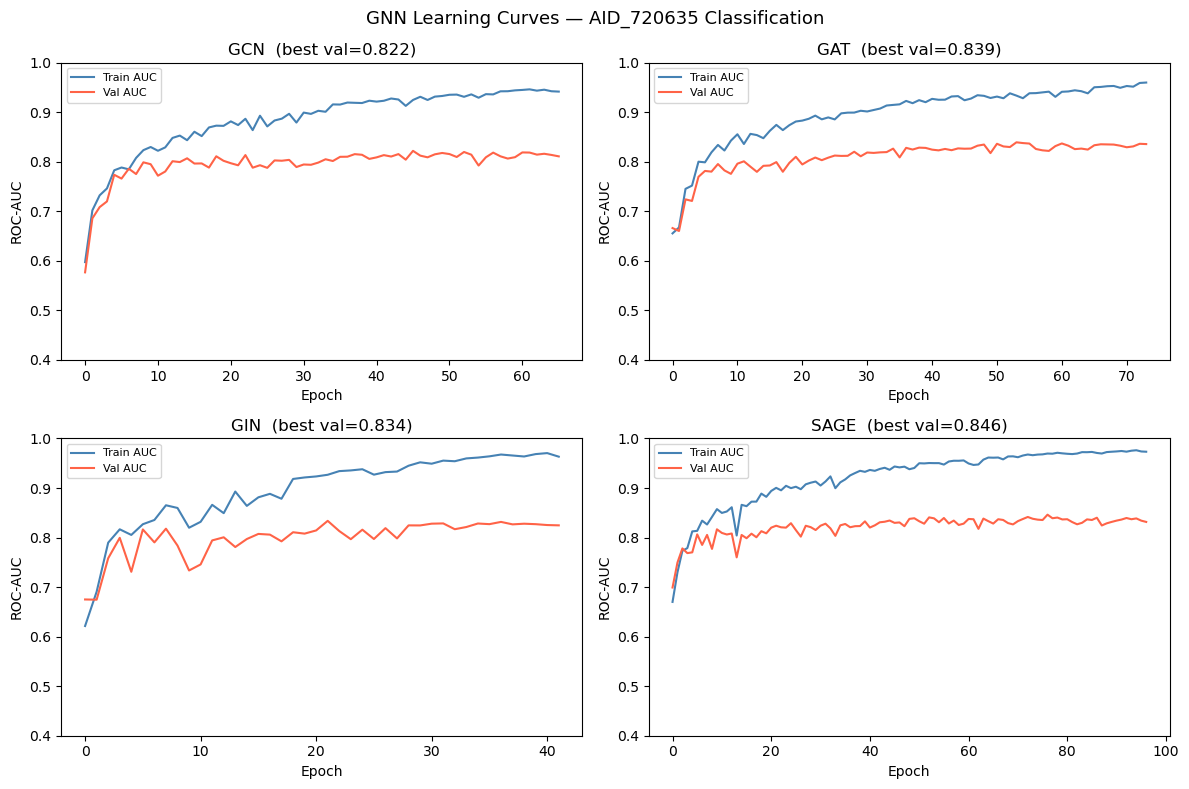

In [28]:
# ── 21. Learning Curves ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={gnn_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — AID_720635 Classification', fontsize=13)
plt.tight_layout(); plt.savefig('gnn_learning_curves.png',dpi=150); plt.show()


In [29]:
# ── 22. GNN Test Evaluation ──────────────────────────────────────────────────
gnn_probs_test = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    probs, _, _ = gnn_eval(model, test_loader, DEVICE)
    gnn_probs_test[arch] = probs

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Test Set ──')
display(df_gnn_test.set_index(['Model','CPT']))


── GNN — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         80.0         63.1  71.6   0.8067  0.1184  0.1600     71.6   
      0.8         50.0         88.4  69.2   0.8067  0.1184  0.2062     69.2   
GAT   0.5         80.0         60.9  70.5   0.7838  0.1405  0.1506     70.5   
      0.8         50.0         88.3  69.1   0.7838  0.1405  0.2054     69.1   
GIN   0.5         70.0         77.3  73.6   0.8004  0.1687  0.1988     73.6   
      0.8         36.0         93.4  64.7   0.8004  0.1687  0.2011     64.7   
SAGE  0.5         68.0         74.5  71.2   0.7812  0.1115  0.1727     71.2   
      0.8         50.0         89.5  69.7   0.7812  0.1115  0.2203     69.7   

               F1  
Model CPT          
GCN   0.5  0.1292  
      0.8  0.2066  
GAT   0.5  0.1231  
      0.8  0.2058  
GIN   0.5  0.1703  
      0.8  0.2222  
SAGE  0.5  0.1511  
      0.8  0.2212

---
## Step 7 — Consensus Model (All Classical + GNN)


In [30]:
# ── 23. Consensus: Average All Model Probabilities ───────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

# Classical-only consensus
cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

# GNN-only consensus
gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL TEST SET COMPARISON ──')
display(df_final.set_index(['Model','CPT'])) #to check if we can 3rd categoruy for inactive


── FULL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         20.0         98.6  59.3   0.8202  0.2216   
                    0.8          4.0        100.0  52.0   0.8202  0.2216   
SVM                 0.5         20.0         98.6  59.3   0.8144  0.1817   
                    0.8          0.0        100.0  50.0   0.8144  0.1817   
XGBoost             0.5         46.0         92.8  69.4   0.8021  0.1606   
                    0.8         34.0         97.1  65.5   0.8021  0.1606   
GCN                 0.5         80.0         63.1  71.6   0.8067  0.1184   
                    0.8         50.0         88.4  69.2   0.8067  0.1184   
GAT                 0.5         80.0         60.9  70.5   0.7838  0.1405   
                    0.8         50.0         88.3  69.1   0.7838  0.1405   
GIN                 0.5         70.0         77.3  73.6   0.8004  0.1687   
                    0.8         36.0         93.4  64.7   0.8004  0.1687   
SAGE                0.5         68.0         74.5  71.2   0.7812  0.1115   
                    0.8         50.0         89.5  69.7   0.7812  0.1115   
Consensus           0.5         64.0         85.8  74.9   0.8354  0.1928   
                    0.8          6.0         99.6  52.8   0.8354  0.1928   
Consensus-Classical 0.5         32.0         96.8  64.4   0.8429  0.2396   
                    0.8          2.0        100.0  51.0   0.8429  0.2396   
Consensus-GNN       0.5         70.0         72.6  71.3   0.8091  0.1541   
                    0.8         46.0         92.5  69.2   0.8091  0.1541   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.2385     59.3  0.2500  
                    0.8  0.1967     52.0  0.0769  
SVM                 0.5  0.2385     59.3  0.2500  
                    0.8  0.0000     50.0  0.0000  
XGBoost             0.5  0.2513     69.4  0.2614  
                    0.8  0.2869     65.5  0.3119  
GCN                 0.5  0.1600     71.6  0.1292  
                    0.8  0.2062     69.2  0.2066  
GAT                 0.5  0.1506     70.5  0.1231  
                    0.8  0.2054     69.1  0.2058  
GIN                 0.5  0.1988     73.6  0.1703  
                    0.8  0.2011     64.7  0.2222  
SAGE                0.5  0.1727     71.2  0.1511  
                    0.8  0.2203     69.7  0.2212  
Consensus           0.5  0.2464     74.9  0.2246  
                    0.8  0.1297     52.8  0.1017  
Consensus-Classical 0.5  0.2597     64.4  0.2857  
                    0.8  0.1391     51.0  0.0392  
Consensus-GNN       0.5  0.1697     71.3  0.1464  
                    0.8  0.2447     69.2  0.2541

---
## Step 8 — Applicability Domain


AD threshold  : 0.6504
Test in AD    : 514/925 (55.6%)
  AD-filtered Sensitivity: 90.9
  AD-filtered Specificity: 84.8
  AD-filtered CCR: 87.9
  AD-filtered ROC-AUC: 0.9342
  AD-filtered MCC: 0.7417


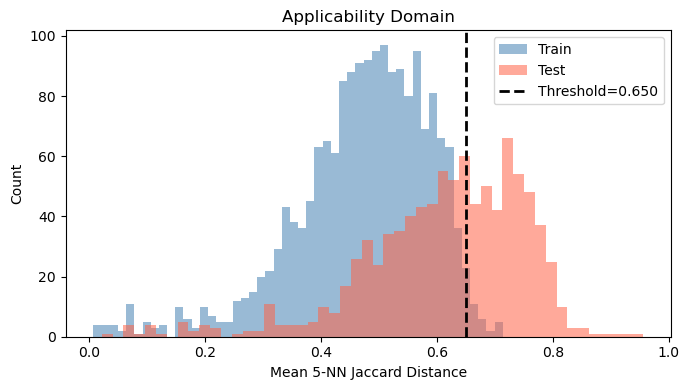

In [ ]:
# ── 24. AD — k-NN Jaccard ────────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain'); ax.legend()
plt.tight_layout(); plt.savefig('ad_dist.png',dpi=150); plt.show()


---
## Step 9 — Final Summary


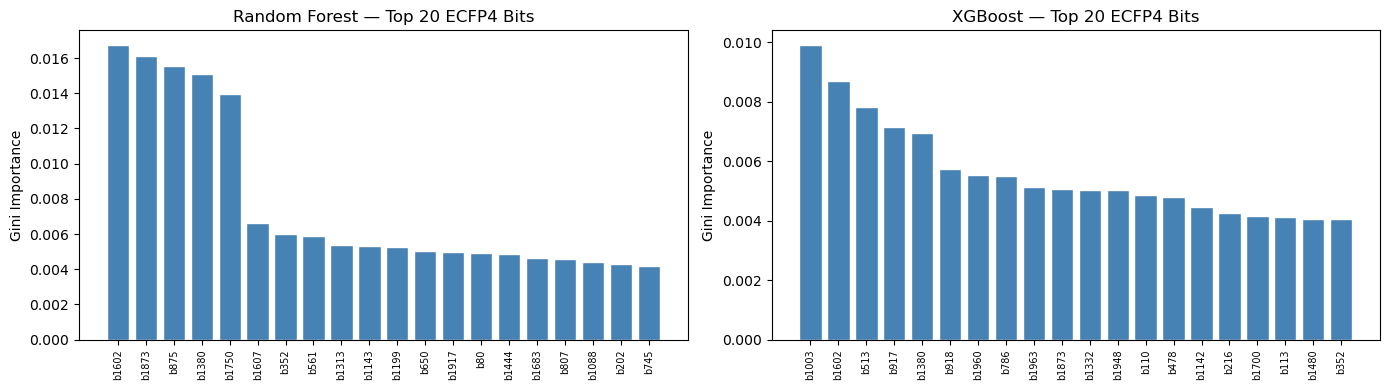

In [ ]:
# ── 25. Feature Importance — RF & XGBoost ────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('feat_importance.png',dpi=150); plt.show()


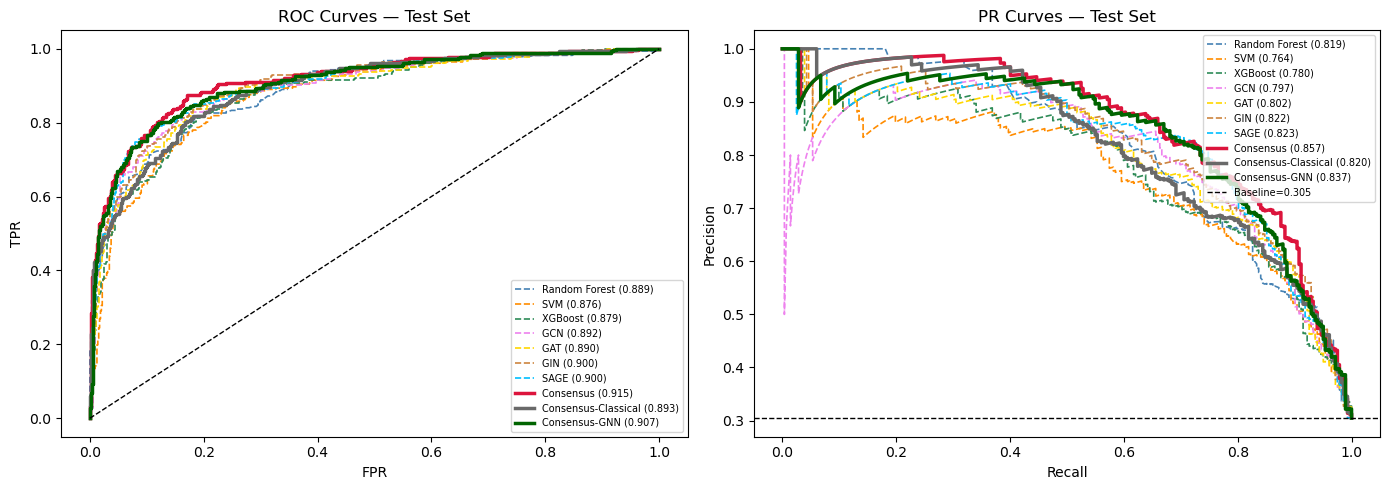

In [ ]:
# ── 26. ROC Curves — All Models ──────────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Test Set'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Test Set'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('roc_pr_all.png',dpi=150); plt.show()


In [ ]:
# ── 27. Ranked Summary Table (CPT-1) ─────────────────────────────────────────
summary_cpt1 = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('ROC-AUC', ascending=False)
print('═'*90)
print('FINAL RANKING — AID_720635 Binary Toxicity (CPT-1, threshold≥0.50)')
print('80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features')
print('═'*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('qsar_mito_final_results.csv')
print('Saved → qsar_mito_final_results.csv')


══════════════════════════════════════════════════════════════════════════════════════════
FINAL RANKING — AID_720635 Binary Toxicity (CPT-1, threshold≥0.50)
80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features
══════════════════════════════════════════════════════════════════════════════════════════


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Consensus,85.8,83.5,84.7,0.9147,0.8570,0.6588,84.7,0.7683
Consensus-GNN,84.4,82.1,83.3,0.9073,0.8366,0.6303,83.3,0.7496
GIN,84.4,80.1,82.2,0.9005,0.8223,0.6071,82.2,0.7346
SAGE,84.0,82.4,83.2,0.9001,0.8233,0.6309,83.2,0.7500
Consensus-Classical,81.9,81.8,81.9,0.8932,0.8197,0.6055,81.9,0.7333
GCN,82.6,82.0,82.3,0.8924,0.7972,0.6134,82.3,0.7385
GAT,83.7,81.2,82.4,0.8899,0.8019,0.6134,82.4,0.7387
Random Forest,81.9,80.2,81.1,0.8893,0.8192,0.5875,81.1,0.7219
XGBoost,81.2,81.2,81.2,0.8795,0.7805,0.5922,81.2,0.7247



Applicability Domain coverage: 55.6%
Saved → qsar_mito_final_results.csv


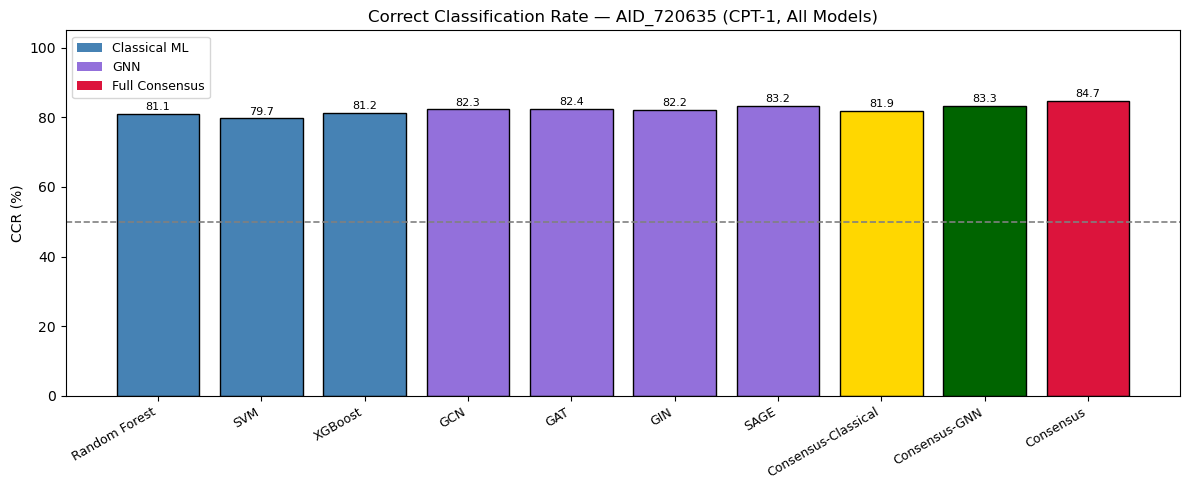

In [ ]:
# ── 28. CCR Comparison Bar Chart ─────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — AID_720635 (CPT-1, All Models)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
ax.legend()
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout(); plt.savefig('ccr_all_models.png',dpi=150); plt.show()


Best model (ROC-AUC): Consensus
              precision    recall  f1-score   support

 Inactive(0)       0.93      0.84      0.88       643
   Active(1)       0.70      0.86      0.77       282

    accuracy                           0.84       925
   macro avg       0.81      0.85      0.82       925
weighted avg       0.86      0.84      0.85       925



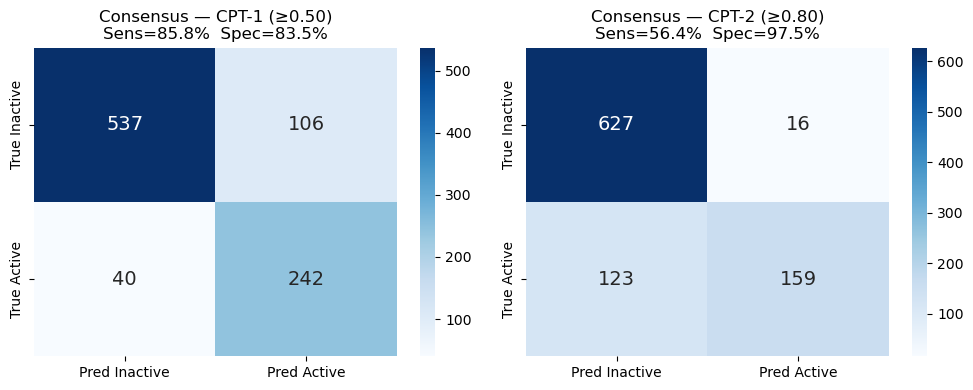

In [ ]:
# ── 29. Best Model Report ─────────────────────────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['Inactive(0)','Active(1)']))

# Confusion matrix
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (≥0.50)','CPT-2 (≥0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred Inactive','Pred Active'],
                yticklabels=['True Inactive','True Active'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('confusion_final.png',dpi=150); plt.show()


---
## Step 10 — Single Compound Prediction

Paste any SMILES below to run it through all 7 trained models and get a consensus toxicity prediction.


Compound : Nc1ccc(-c2ccc(F)cc2)cc1
Canonical: Nc1ccc(-c2ccc(F)cc2)cc1
Mol. Weight: 187.22 Da  |  Atoms: 14

════════════════════════════════════════════════════════════
 INDIVIDUAL MODEL PROBABILITIES (P(Active))
════════════════════════════════════════════════════════════
  Model                   P(Active)    CPT-1    CPT-2
  -------------------------------------------------------
  Random Forest              0.6033   ACTIVE  inactive  
  SVM                        0.5055   ACTIVE  inactive  
  XGBoost                    0.5143   ACTIVE  inactive  
  GCN                        0.8004   ACTIVE   ACTIVE  
  GAT                        0.7289   ACTIVE  inactive  
  GIN                        0.5069   ACTIVE  inactive  
  SAGE                       0.8050   ACTIVE   ACTIVE  
  Consensus-Classical        0.5410   ACTIVE  inactive  
  Consensus-GNN              0.7103   ACTIVE  inactive  
  CONSENSUS (all 7)          0.6377   ACTIVE  inactive  ◄◄
════════════════════════════════════════════

[11:00:25] DEPRECATION WARNING: please use MorganGenerator


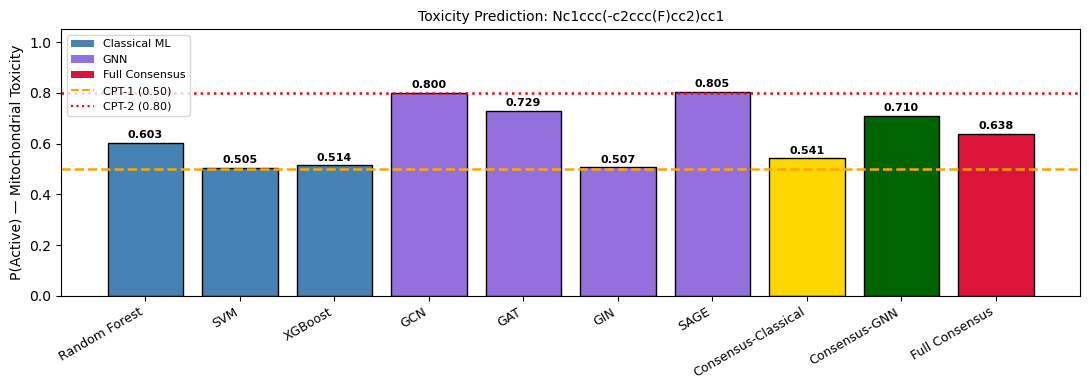

In [ ]:
# ── 30. Single Compound Prediction ───────────────────────────────────────────
# ► Change TEST_SMILES to any molecule you want to predict.
# ► Set TRUE_LABEL = 1 (Active) or 0 (Inactive) if you know it, else None.
# ─────────────────────────────────────────────────────────────────────────────

from rdkit.Chem import Descriptors   # needed for MolWt

TEST_SMILES  = "Nc1ccc(-c2ccc(F)cc2)cc1"  
TRUE_LABEL   = None                       

# ── Step A: Parse & canonicalise ─────────────────────────────────────────────
mol = Chem.MolFromSmiles(TEST_SMILES)
if mol is None:
    raise ValueError(f"RDKit could not parse SMILES: {TEST_SMILES!r}  — check for typos.")

canon = Chem.MolToSmiles(mol)
mw    = Descriptors.MolWt(mol)
print(f"Compound : {TEST_SMILES}")
print(f"Canonical: {canon}")
print(f"Mol. Weight: {mw:.2f} Da  |  Atoms: {mol.GetNumAtoms()}")

# ── Step B: Morgan fingerprint (for classical ML + AD) ────────────────────────
fp_arr = smiles_to_ecfp4(canon)          # reuses function from Cell 5
X_query = fp_arr.reshape(1, -1)          # shape (1, 2048)

# ── Step C: Build graph (for GNN) ─────────────────────────────────────────────
graph_query = mol_to_graph(canon, label=0)   # label=0 is placeholder
query_loader = DataLoader([graph_query], batch_size=1, shuffle=False)

# ── Step D: Classical ML probabilities ────────────────────────────────────────
cl_query_probs = {}
for name, clf in classical.items():                # RF, SVM, XGBoost
    cl_query_probs[name] = float(clf.predict_proba(X_query)[0, 1])

# ── Step E: GNN probabilities ─────────────────────────────────────────────────
gnn_query_probs = {}
for arch, state in gnn_best_models.items():        # GCN, GAT, GIN, SAGE
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        batch = next(iter(query_loader)).to(DEVICE)
        logit = model(batch.x, batch.edge_index, batch.batch)
        gnn_query_probs[arch] = float(torch.sigmoid(logit).item())

# ── Step F: Consensus ─────────────────────────────────────────────────────────
all_query_probs = {**cl_query_probs, **gnn_query_probs}
consensus_q     = float(np.mean(list(all_query_probs.values())))
cl_consensus_q  = float(np.mean(list(cl_query_probs.values())))
gnn_consensus_q = float(np.mean(list(gnn_query_probs.values())))

# ── Step G: Applicability Domain check ───────────────────────────────────────
d_query, _ = nn_ad.kneighbors(X_query)
md_query   = float(d_query.mean())
in_domain  = md_query <= ad_thr

# ── Step H: Pretty print ─────────────────────────────────────────────────────
print("\n" + "═"*60)
print(" INDIVIDUAL MODEL PROBABILITIES (P(Active))")
print("═"*60)
print(f"  {'Model':<22} {'P(Active)':>10}  {'CPT-1':>7}  {'CPT-2':>7}")
print("  " + "-"*55)
for name, p in {**all_query_probs,
                'Consensus-Classical': cl_consensus_q,
                'Consensus-GNN'      : gnn_consensus_q,
                'CONSENSUS (all 7)'  : consensus_q}.items():
    pred1 = "ACTIVE" if p >= 0.5 else "inactive"
    pred2 = "ACTIVE" if p >= 0.8 else "inactive"
    marker = "◄◄" if "CONSENSUS" in name else ""
    print(f"  {name:<22} {p:>10.4f}  {pred1:>7}  {pred2:>7}  {marker}")

print("═"*60)
print(f"\n  CONSENSUS PROBABILITY : {consensus_q:.4f}")

cpt1_call = "⚠  ACTIVE (Mitochondrially Toxic)" if consensus_q >= 0.5 else "✓  INACTIVE (Non-Toxic)"
cpt2_call = "⚠  ACTIVE (High-confidence)"        if consensus_q >= 0.8 else "✓  INACTIVE / uncertain"

print(f"  CPT-1 (≥0.50) verdict: {cpt1_call}")
print(f"  CPT-2 (≥0.80) verdict: {cpt2_call}")

ad_msg = f"INSIDE applicability domain  (dist={md_query:.4f} ≤ {ad_thr:.4f})" \
         if in_domain else \
         f"OUTSIDE applicability domain (dist={md_query:.4f} > {ad_thr:.4f}) — prediction may be unreliable"
print(f"\n  AD check   : {ad_msg}")

if TRUE_LABEL is not None:
    lbl_str = "Active (1)" if TRUE_LABEL == 1 else "Inactive (0)"
    correct = (consensus_q >= 0.5) == (TRUE_LABEL == 1)
    print(f"\n  True label : {lbl_str}  →  Prediction {'CORRECT ✓' if correct else 'WRONG ✗'}")

print("═"*60)

# ── Step I: Bar chart ─────────────────────────────────────────────────────────
plot_names  = list(all_query_probs.keys()) + ['Consensus-Classical','Consensus-GNN','Full Consensus']
plot_probs  = list(all_query_probs.values()) + [cl_consensus_q, gnn_consensus_q, consensus_q]
plot_colors = (['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson'])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(plot_names, plot_probs, color=plot_colors, edgecolor='black')
ax.axhline(0.5, color='orange', lw=1.8, ls='--', label='CPT-1 (0.50)')
ax.axhline(0.8, color='red',    lw=1.8, ls=':',  label='CPT-2 (0.80)')
for b, p in zip(bars, plot_probs):
    ax.text(b.get_x() + b.get_width()/2, p + 0.01, f'{p:.3f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_ylabel('P(Active) — Mitochondrial Toxicity')
ax.set_title(f'Toxicity Prediction: {canon}', fontsize=10)
ax.set_xticklabels(plot_names, rotation=30, ha='right', fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus'),
                   plt.Line2D([0],[0],color='orange',ls='--',label='CPT-1 (0.50)'),
                   plt.Line2D([0],[0],color='red',   ls=':' ,label='CPT-2 (0.80)')],
          fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('single_compound_prediction.png', dpi=150)
plt.show()
